<a href="https://colab.research.google.com/github/NietoEmmanuel/SIMULACION-II/blob/main/Simulacion_Integral_Estocastica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integral estocástica

Simulamos la variable aleatoria

$$I=\int_0^1 W_s^2\,ds$$

donde $W_s$ es un movimiento browniano estándar. Como cada trayectoria de $W$ es distinta, cada vez que calculamos la integral obtenemos un número diferente, por eso $I$ es una variable aleatoria.

Lo que vamos a hacer:

1. Simular trayectorias del movimiento browniano.
2. Aproximar la integral de cada trayectoria con sumas de Riemann.
3. Repetir el proceso muchas veces para estimar la esperanza y la varianza de $I$.
4. Comparar con los valores que se obtienen de forma analítica.

## Resultados teóricos

Sea $I_t=\int_0^t W_s^2\,ds$. De forma analítica (con Fubini y $Cov(B_x,B_y)=\min\{x,y\}$) se obtiene

$$E[I_t]=\frac{t^2}{2},\qquad Var[I_t]=\frac{t^4}{3}$$

Para $t=1$ la **media = 1/2** y **varianza = 1/3**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## Simulación del movimiento browniano


In [3]:
def brown(T,L):
    lista = []
    w_0 = 0
    dt = T/(L-1)
    for _ in range(1,L):
        dw = np.random.normal(0,1)
        w_1 = w_0 + np.sqrt(dt)*dw
        lista.append(w_1)

        w_0 = w_1
    lista.insert(0,0)
    return lista

Una trayectoria de ejemplo:

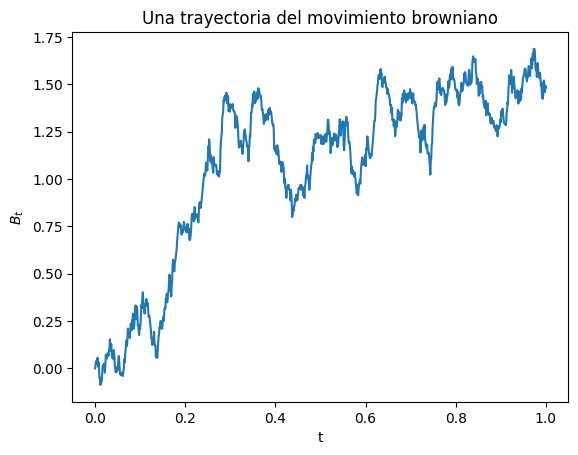

In [4]:
B = brown(1,1000)
t = np.linspace(0,1,1000)

plt.plot(t,B)
plt.title("Una trayectoria del movimiento browniano")
plt.xlabel("t")
plt.ylabel("$B_t$")
plt.show()

## Integral con sumas de Riemann

Para cada trayectoria $\omega$, la función $s\mapsto B_s(\omega)$ es continua, así que $s\mapsto B_s(\omega)^2$ también y es integrable. Para una partición $0=t_0<t_1<\dots<t_n=t$ definimos la suma de Riemann

$$I^{(n)}(\omega)=\sum_{k=1}^{n}B_{t_k^*}(\omega)^2\,(t_k-t_{k-1}),\qquad t_k^*\in[t_{k-1},t_k]$$

y el valor de la integral es $\lim_{n\to\infty}I^{(n)}(\omega)$. Tomamos el extremo izquierdo, $t_k^*=t_{k-1}$:

$$\int_{0}^{t}B_s^2\,ds\approx\sum_{i=0}^{n-1}B_{t_i}^2\,(t_{i+1}-t_i)$$

In [5]:
def integral(a,b,n):
    suma = 0
    t = np.linspace(a,b,n)
    B = np.array(brown(b-a,n))
    B = B**2
    for i in range(n-1):
        suma += B[i]*(t[i+1]-t[i])
    return float(suma)

Graficamos area bajo la trayectoria $W_s^2$

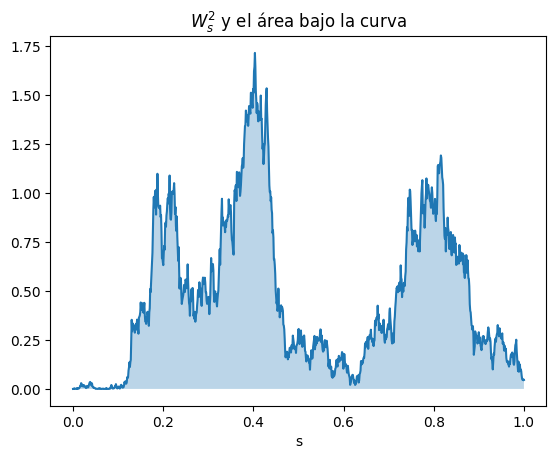

In [7]:
n = 1000
t = np.linspace(0,1,n)
B2 = np.array(brown(1,n))**2

plt.plot(t,B2)
plt.fill_between(t,B2,alpha=0.3)
plt.title("$W_s^2$ y el área bajo la curva")
plt.xlabel("s")
plt.show()

Cada vez que corremos la función usamos una trayectoria nueva, así que el resultado cambia:

In [9]:
print(integral(0,1,1000))

0.8853037337889033


## Media y varianza simuladas

Repetimos la integral muchas veces (cada una con una trayectoria distinta) para calcular la media y la varianza de la muestra:

In [10]:
N = 10000    # número de simulaciones
n = 1000    # puntos de cada trayectoria

muestra = []
for i in range(N):
    muestra.append(integral(0,1,n))

media = np.mean(muestra)
varianza = np.var(muestra)
print(f"La media es: {media}")
print(f"La varianza es: {varianza}")

La media es: 0.4961592367323079
La varianza es: 0.3281146321827966


## Conclusión

La media y la varianza simuladas quedan cerca de $1/2$ y $1/3$, que son los valores que obtuvimos de forma analítica.